**Objetivo:** inspeccionar los clips de boca generados por ViSpeR antes de construir nuestro `Dataset` de PyTorch.

Vamos a comprobar:
1. Que los archivos existan y puedan abrirse.
2. Resolución, FPS y cantidad de frames.
3. Correspondencia entre los frames reales y `metadata.json`.
4. distribución de longitudes.
5. Calidad visual de algunos clips y si afecta bajarla 

no pienso procesar todo denuevo, neithe should you

## 1. Entorno e imports

In [9]:
import sys
from pathlib import Path
import json

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.executable)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python: c:\Users\Angelina\miniforge3\envs\visper\python.exe
OpenCV: 4.10.0
NumPy: 1.26.4
Pandas: 2.3.3


## 2. Cargar metadata

In [10]:
DATA_DIR = Path(r"D:\ViSpeR\clips")
METADATA_PATH = DATA_DIR / "metadata.json"

with open(METADATA_PATH, "r", encoding="utf-8") as f:
    metadata = json.load(f)

print("Clips registrados:", len(metadata))
print("Metadata:", METADATA_PATH)

sample_path = next(iter(metadata))
sample_item = metadata[sample_path]

print("\nRuta de ejemplo:", sample_path)
print("Datos:", sample_item)

Clips registrados: 2439
Metadata: D:\ViSpeR\clips\metadata.json

Ruta de ejemplo: D:\ViSpeR\videos\0YEeb-WLF2w\00000.mp4
Datos: {'label': ' La ficción es una herramienta poderosa', 'length': 108}


## 3. Comprobar existencia de archivos

Las claves de `metadata.json` contienen las rutas de los clips. Primero verificamos si esas rutas siguen siendo válidas.

In [25]:
from pathlib import Path

collisions = []
different = []

for raw_path, item in metadata.items():
    p = Path(raw_path)

    if not p.is_file():
        try:
            alternative = Path(r"D:\ViSpeR\clips\videos") / p.relative_to(
                Path(r"D:\ViSpeR\videos")
            )
        except ValueError:
            continue

        if alternative.is_file() and str(alternative) in metadata:
            existing_item = metadata[str(alternative)]

            if item == existing_item:
                collisions.append((raw_path, str(alternative)))
            else:
                different.append((raw_path, str(alternative)))

print("Colisiones idénticas:", len(collisions))
print("Colisiones con datos diferentes:", len(different))

Colisiones idénticas: 1135
Colisiones con datos diferentes: 0


In [ ]:
import json
import shutil
from pathlib import Path

METADATA_PATH = Path(r"D:\ViSpeR\clips\metadata.json")
BACKUP_PATH = METADATA_PATH.with_suffix(".json.bak")
backup_path = BACKUP_PATH

old_root = Path(r"D:\ViSpeR\videos")
new_root = Path(r"D:\ViSpeR\clips\videos")

# 1. Backup
if not backup_path.exists():
    shutil.copy2(METADATA_PATH, backup_path)
    print("Backup creado:", backup_path)
else:
    print("Backup existente, se conserva:", backup_path)

shutil.copy2(METADATA_PATH, BACKUP_PATH)

# 2. Actualizar únicamente rutas verificadas
updated_metadata = {}
updated_count = 0
unresolved_count = 0
duplicate_count = 0

for raw_path, item in metadata.items():
    old_path = Path(raw_path)

    if old_path.is_file():
        new_path = raw_path

    else:
        try:
            relative_path = old_path.relative_to(old_root)
            alternative = new_root / relative_path
        except ValueError:
            alternative = None

        if alternative is not None and alternative.is_file():
            new_path = str(alternative)
            updated_count += 1
        else:
            new_path = raw_path
            unresolved_count += 1

    if new_path in updated_metadata:
        if updated_metadata[new_path] == item:
            duplicate_count += 1
            continue
        else:
            raise ValueError(
                f"Colisión con datos diferentes: {new_path}"
            )
    updated_metadata[new_path] = item
print("Duplicados idénticos descartados:", duplicate_count)
# 3. Guardar de forma segura
temp_path = METADATA_PATH.with_suffix(".json.tmp")

with open(temp_path, "w", encoding="utf-8") as f:
    json.dump(updated_metadata, f, ensure_ascii=False, indent=2)

temp_path.replace(METADATA_PATH)

# Actualizar también la variable del notebook
metadata = updated_metadata

print("Metadata actualizado.")
print("Rutas corregidas:", updated_count)
print("Registros sin resolver conservados:", unresolved_count)
print("Registros totales:", len(metadata))
print("Backup:", BACKUP_PATH)


Backup existente, se conserva: D:\ViSpeR\clips\metadata.json.bak
Duplicados idénticos descartados: 1135
Metadata actualizado.
Rutas corregidas: 1135
Registros sin resolver conservados: 0
Registros totales: 1304
Backup: D:\ViSpeR\clips\metadata.json.bak


In [28]:
clip_paths = [Path(path) for path in metadata.keys()]

existing_count = sum(path.is_file() for path in clip_paths)
missing_paths = [path for path in clip_paths if not path.is_file()]

print("Registrados:", len(clip_paths))
print("Encontrados:", existing_count)
print("Faltantes:", len(missing_paths))

if missing_paths:
    print("\nPrimeras rutas faltantes:")
    for path in missing_paths[:10]:
        print(path)

Registrados: 1304
Encontrados: 1304
Faltantes: 0


## 4. Inspeccionar un clip

In [29]:
# Elegimos un clip existente para inspeccionarlo.
valid_paths = [path for path in clip_paths if path.is_file()]
assert valid_paths, "No se encontraron clips. Revisar las rutas de metadata.json."

clip_path = valid_paths[0]
clip_info = metadata[str(clip_path)]

cap = cv2.VideoCapture(str(clip_path))

if not cap.isOpened():
    raise RuntimeError(f"No se pudo abrir el video: {clip_path}")

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print("Clip:", clip_path)
print("FPS:", fps)
print("Frames reales:", frame_count)
print("Resolución:", f"{width}x{height}")
print("Frames en metadata:", clip_info["length"])
print("Duración real (s):", frame_count / fps if fps else None)
print("Duración metadata (s):", clip_info["length"] / 25)

cap.release()

Clip: D:\ViSpeR\clips\videos\0YEeb-WLF2w\00000.mp4
FPS: 25.0
Frames reales: 108
Resolución: 96x96
Frames en metadata: 108
Duración real (s): 4.32
Duración metadata (s): 4.32


## 5. Visualizar frames de un clip

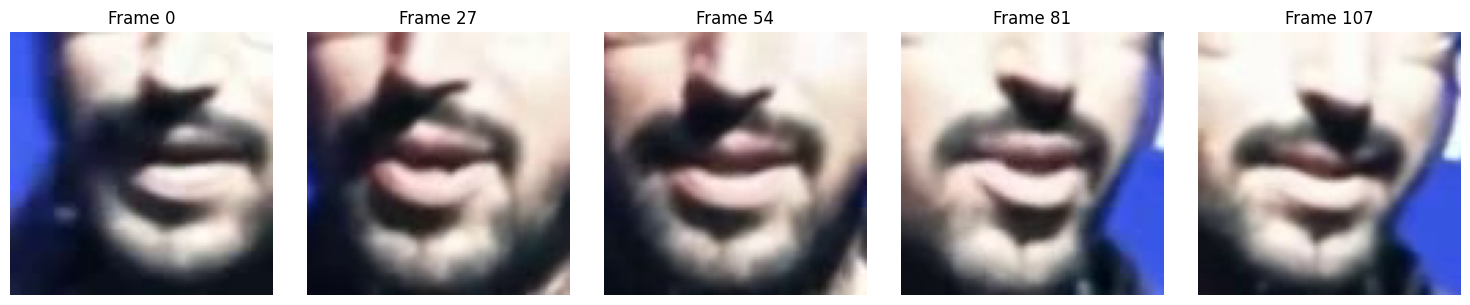

In [30]:
def show_clip_frames(path, frame_indices=None):
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise RuntimeError(f"No se pudo abrir: {path}")

    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if frame_indices is None:
        frame_indices = sorted(set([0, total // 4, total // 2, 3 * total // 4, total - 1]))

    frames = []
    for idx in frame_indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ret, frame = cap.read()
        if ret:
            frames.append((idx, cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)))

    cap.release()

    if not frames:
        print("No se pudieron leer frames.")
        return

    fig, axes = plt.subplots(1, len(frames), figsize=(3 * len(frames), 3))
    if len(frames) == 1:
        axes = [axes]

    for ax, (idx, frame) in zip(axes, frames):
        ax.imshow(frame, cmap="gray" if frame.ndim == 2 else None)
        ax.set_title(f"Frame {idx}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_clip_frames(clip_path)

## 6. Revisar propiedades de todos los clips

In [31]:
records = []

for path_str, item in metadata.items():
    path = Path(path_str)
    cap = cv2.VideoCapture(str(path))

    if not cap.isOpened():
        records.append({
            "path": path_str,
            "exists": path.is_file(),
            "opened": False,
            "fps": np.nan,
            "frames_real": np.nan,
            "width": np.nan,
            "height": np.nan,
            "frames_metadata": item["length"],
            "label": item["label"]
        })
        continue

    records.append({
        "path": path_str,
        "exists": path.is_file(),
        "opened": True,
        "fps": cap.get(cv2.CAP_PROP_FPS),
        "frames_real": int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
        "width": int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
        "height": int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
        "frames_metadata": item["length"],
        "label": item["label"]
    })
    cap.release()

clips_df = pd.DataFrame(records)

print("Total:", len(clips_df))
print("Videos que OpenCV pudo abrir:", clips_df["opened"].sum())
print("\nResoluciones:")
print(clips_df.groupby(["width", "height"], dropna=False).size())
print("\nFPS:")
print(clips_df["fps"].value_counts(dropna=False).sort_index())

Total: 1304
Videos que OpenCV pudo abrir: 1304

Resoluciones:
width  height
96     96        1304
dtype: int64

FPS:
fps
25.0    1304
Name: count, dtype: int64


## 7. Consistencia entre metadata y archivos

In [32]:
opened_df = clips_df[clips_df["opened"]].copy()

print("Diferencias entre frames reales y metadata:",
      (opened_df["frames_real"] != opened_df["frames_metadata"]).sum())

print("Clips con FPS distinto de 25:",
      ((opened_df["fps"] - 25).abs() > 0.01).sum())

print("Clips que no son 96x96:",
      ((opened_df["width"] != 96) | (opened_df["height"] != 96)).sum())

print("\nEjemplos de inconsistencias:")
display(
    opened_df[
        (opened_df["frames_real"] != opened_df["frames_metadata"]) |
        ((opened_df["fps"] - 25).abs() > 0.01) |
        (opened_df["width"] != 96) |
        (opened_df["height"] != 96)
    ][["path", "fps", "frames_real", "frames_metadata", "width", "height"]].head(10)
)

Diferencias entre frames reales y metadata: 0
Clips con FPS distinto de 25: 0
Clips que no son 96x96: 0

Ejemplos de inconsistencias:


,path,fps,frames_real,frames_metadata,width,height


1 espectaculo

## 8. Distribución de longitudes

,frames_metadata,duration_seconds
count,1304.000000,1304.000000
mean,122.309816,4.892393
std,57.515034,2.300601
min,40.000000,1.600000
25%,81.000000,3.240000
50%,112.000000,4.480000
75%,152.000000,6.080000
max,626.000000,25.040000


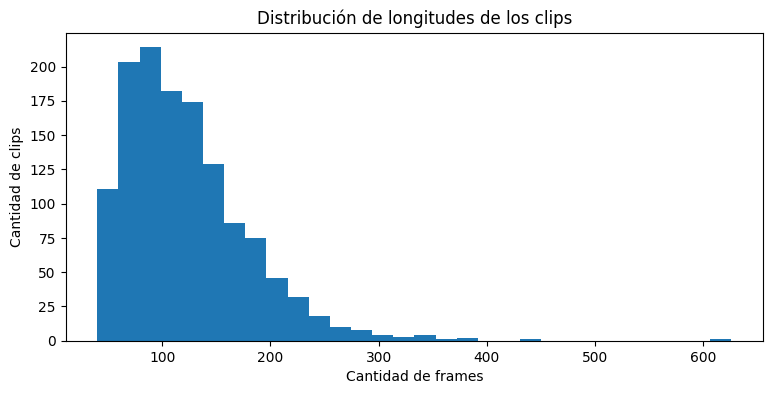

In [33]:
clips_df["duration_seconds"] = clips_df["frames_metadata"] / 25

display(clips_df[["frames_metadata", "duration_seconds"]].describe())

plt.figure(figsize=(9, 4))
plt.hist(clips_df["frames_metadata"].dropna(), bins=30)
plt.xlabel("Cantidad de frames")
plt.ylabel("Cantidad de clips")
plt.title("Distribución de longitudes de los clips")
plt.show()

## 9. Inspección visual de varios clips

In [34]:
import random

def inspect_random_samples(n=5):
    selected_paths = random.sample(valid_paths, n)

    for path in selected_paths:
        info = metadata[str(path)]
        total_frames = info["length"]

        # Elegir 5 frames aleatorios sin repetir
        frame_indices = sorted(
            random.sample(range(total_frames), min(5, total_frames))
        )

        print(f"\nClip: {path.name}")
        print("Transcripción:", info["label"])
        print("Frames seleccionados:", frame_indices)

        show_clip_frames(path, frame_indices=frame_indices)


Clip: 00019.mp4
Transcripción:  Así como tampoco hubiéramos vivido el escándalo de Cambridge Analytica si no hubiera sido porque antes le contamos todo sobre nosotros mismos a Facebook
Frames seleccionados: [46, 77, 89, 139, 148]


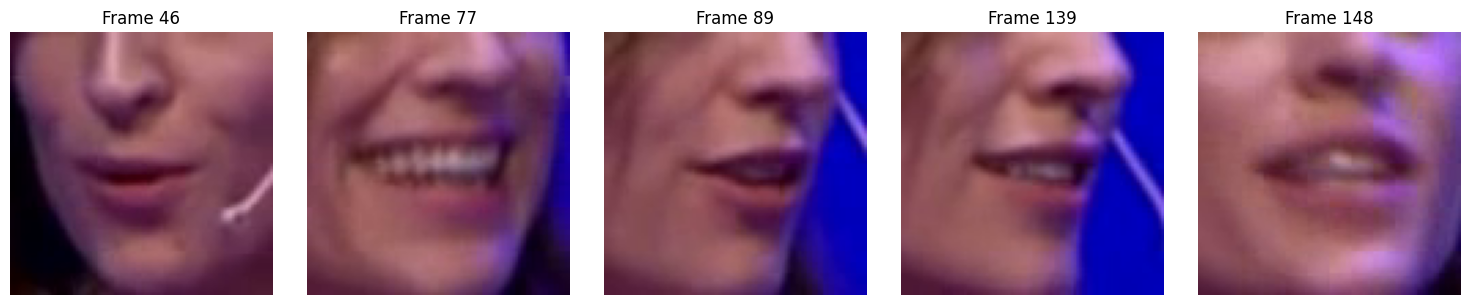


Clip: 00028.mp4
Transcripción:  el catálogo de tal forma que se hacían dueños de hectáreas de selva y por supuesto de terrenos en frente de la playa
Frames seleccionados: [25, 76, 88, 116, 211]


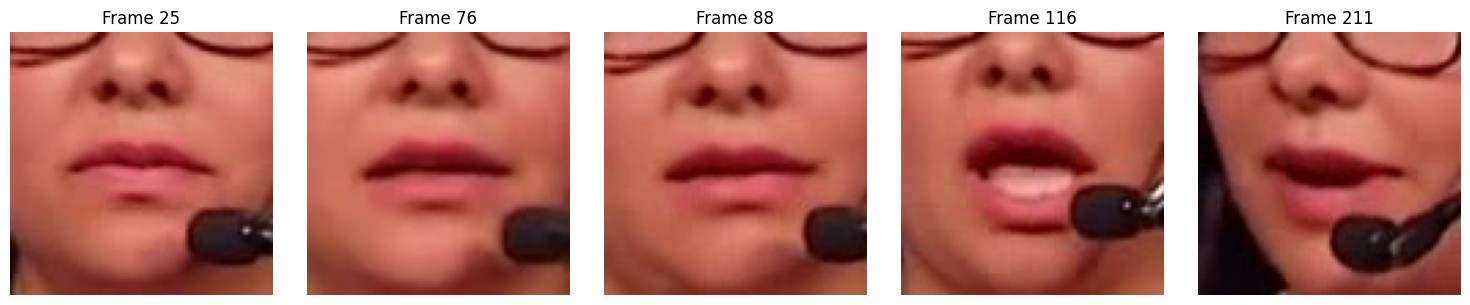


Clip: 00085.mp4
Transcripción: De hecho después vamos a tener acá al geólogo donde su hijo Diego Suárez fue el que descubrió el chilesaurio
Frames seleccionados: [39, 57, 80, 190, 192]


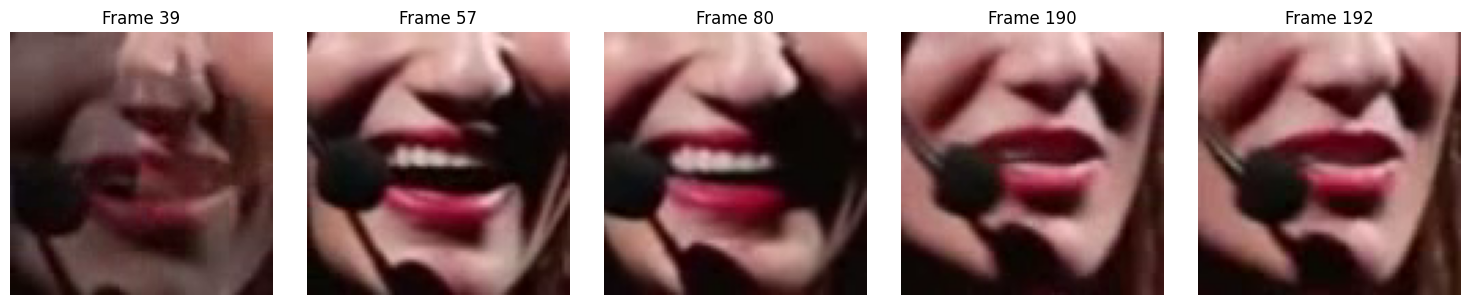


Clip: 00067.mp4
Transcripción:  el poder salir viajar o hacer lo que yo quisiera sin tener que rendir cuentas a nadie o sin tener esa responsabilidad
Frames seleccionados: [83, 144, 156, 160, 170]


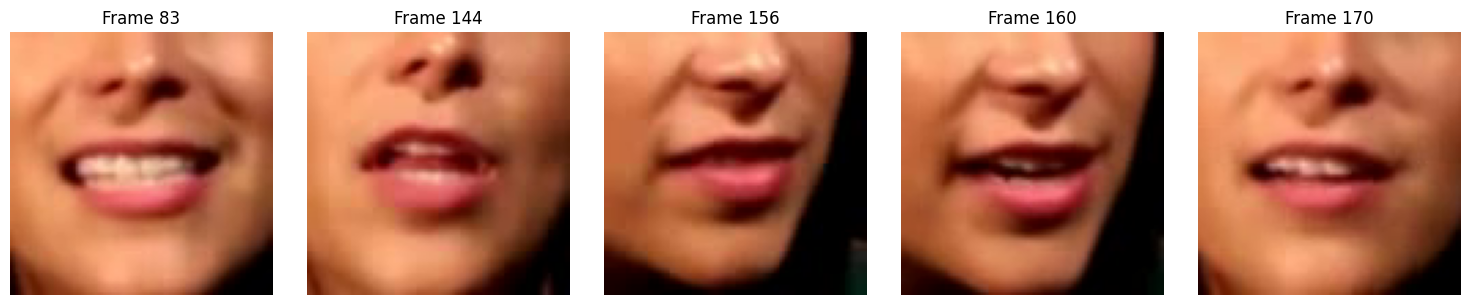


Clip: 00011.mp4
Transcripción:  Es decir pues el Sol no tiene energía
Frames seleccionados: [2, 15, 19, 34, 39]


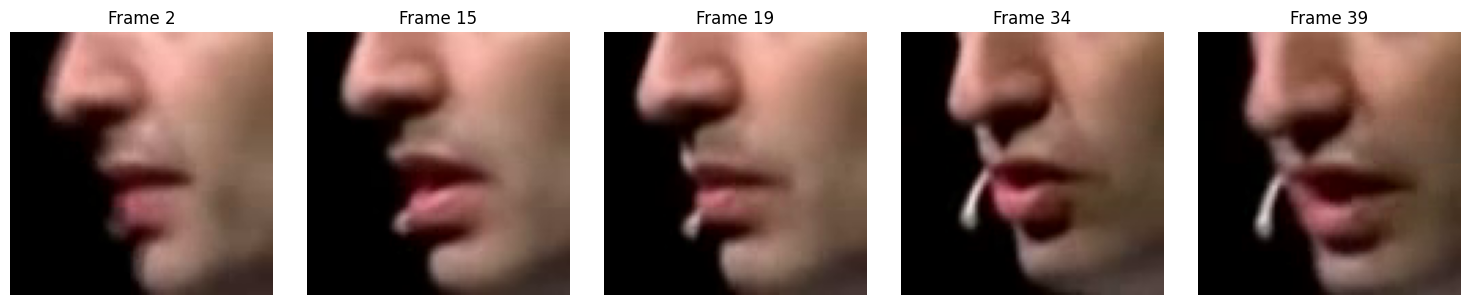

In [37]:
inspect_random_samples(n=5)

arrancamos sin inconsistencias conocidas
